# Physical units: a CNOT in nanoseconds and megahertz

This notebook shows GEOPE working in physical units. Pass `delta_t` as a time quantity and every other physical input must carry its unit too; the optimiser then runs on the usual dimensionless problem, and the results read back as quantities: a gate time in ns, a pulse in MHz or µeV.

The system is a two-qubit transverse-field Ising model: local $X$ and $Y$ controls on each qubit and a fixed $ZZ$ coupling of 5 MHz. We target a CNOT with 20 segments of 25 ns, a 500 ns gate.

**Convention.** A coefficient $c$ multiplies its generator as the basis defines it: $H = \hbar\sum_k c_k G_k$ with unnormalised Paulis. Since $\mathrm{Tr}(X^2) = 2$, a coefficient of 5 MHz on $X$ rotates at a Rabi frequency of 10 MHz, and a $\pi$ pulse takes $1/(4 \cdot 5\ \text{MHz}) = 50$ ns (checked at the end). Hz-family units are cyclic and carry the $2\pi$; `rad_per_ns` is angular; energies convert through $\hbar$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from geope import Gecko, Geope, History, Parameters, construct_full_pauli_basis
from geope.units import MHz, ns, rad_per_ns, ueV

## 1. Quantities

A quantity is a number or array times a unit. It converts with `.to(...)` and does nothing else: no arithmetic, and it can never reach jitted code.

In [2]:
drift = 5 * MHz
print(drift, "=", drift.to(rad_per_ns), "=", drift.to(ueV))
print((1.0 * ueV).to(MHz), " (E / h)")
print(np.array([-20, 20]) * MHz)

5.0 MHz = 0.03141592653589793 rad/ns = 0.020678338484619294 ueV
241.79892420849183 MHz  (E / h)
[-20.  20.] MHz


## 2. The problem, in physical units

`delta_t=25 * ns` turns units on. The drift must then be a quantity too: there is no all-ones default once units are on. Internally the segment duration is exactly 1 and the drift is the rotation angle per segment, $2\pi \cdot 5\,\text{MHz} \cdot 25\,\text{ns} = \pi/4$.

In [3]:
CNOT = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)

params = Parameters(
    basis=construct_full_pauli_basis(2),
    control={1: ["x", "y"], 2: ["x", "y"]},
    drift={(1, 2): ["zz"]},
    drift_values={(1, 2): {"zz": 5 * MHz}},
    target=CNOT,
    piecewise_steps=20,
    delta_t=25 * ns,
    seed=1,
)
print("segment:        ", params.physical.delta_t)
print("gate time:      ", params.physical.total_time)
print("drift:          ", params.physical.drift_parameters.to(MHz))
print("internal dt:    ", params.delta_t)
print("internal drift: ", params.drift_parameters, "=", params.drift_parameters[0] / np.pi, "pi")

segment:         25.0 ns
gate time:       500.0 ns
drift:           [5.] MHz
internal dt:     1.0
internal drift:  [0.78539816] = 0.25 pi


## 3. Optimise

Nothing about the optimiser changes: it sees the dimensionless problem it always has.

In [4]:
opt = Geope(params, history=History())
opt.optimize(max_steps=200, precision=1 - 1e-6)
print(f"fidelity {float(params.fidelity):.8f} after {opt.history.steps[-1]} steps")

fidelity 1.00000000 after 7 steps


## 4. Read the pulse back in physical units

`params.physical` returns quantities. Amplitudes default to the angular partner of the time unit (`rad/ns` here); `.to(MHz)` or `.to(ueV)` convert.

In [5]:
control_idx = np.where(params.projected_indices)[0]
labels = [params.basis.labels[i] for i in control_idx]

pulse = params.physical.basis_coefficients          # shape (20, 15), in rad/ns
amps = pulse.to(MHz).value[:, control_idx]           # the four controls, in MHz
peak = np.abs(amps).max()
print("gate time:", params.physical.total_time)
print(f"peak control amplitude: {peak:.3f} MHz = {float((peak * MHz).to(ueV).value):.4f} ueV")
print("first segment:", {k: v.to(MHz) for k, v in params.physical.to_dict()[1].items()})

gate time: 500.0 ns
peak control amplitude: 8.883 MHz = 0.0367 ueV
first segment: {'x': -4.525137884861896 MHz, 'y': 2.316793701821654 MHz}


## 5. Bound the amplitude with `Gecko`

Bounds are quantities too. `Gecko.bound` moves the pulse within the null space of the Jacobian, so the fidelity is preserved while the violation shrinks: it reduces rather than clamps.

In [6]:
lo, hi = -5 * MHz, 5 * MHz
gk = Gecko(params)
success, iters = gk.bound(
    {"x": (lo, hi), "y": (lo, hi)}, max_bounding_steps=300, bounding_rate=0.05
)
amps = params.physical.basis_coefficients.to(MHz).value[:, control_idx]
print(f"peak {peak:.3f} -> {np.abs(amps).max():.3f} MHz (limit {hi}), "
      f"fidelity {float(params.fidelity):.8f}, {iters} iterations")

[170/300] [Fidelity = 0.9994524786053354] Bounding : cost = 0.09797113000391633 (aim = 0.1)                        


peak 8.883 -> 5.634 MHz (limit 5.0 MHz), fidelity 0.99945248, 170 iterations


## 6. The pulse against physical time

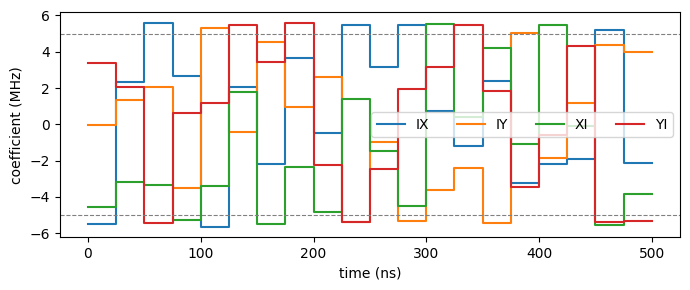

In [7]:
t = np.arange(params.piecewise_steps + 1) * float(params.physical.delta_t.value)   # ns

fig, ax = plt.subplots(figsize=(7, 3))
for k, label in enumerate(labels):
    ax.step(t, np.append(amps[:, k], amps[-1, k]), where="post", label=label)
for sign in (+1, -1):
    ax.axhline(sign * float(hi.value), color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("time (ns)")
ax.set_ylabel("coefficient (MHz)")
ax.legend(ncol=4)
plt.tight_layout()
plt.show()

## 7. The factor of 2, checked

A 5 MHz coefficient on $X$ held for 50 ns should be a $\pi$ pulse (up to a global phase). The chart computes $U = \exp(-i\,\Delta t\,c\,X)$ with $c$ in rad/s, so:

In [8]:
from scipy.linalg import expm

X = np.array([[0, 1], [1, 0]], dtype=complex)
c = float((5 * MHz).to("rad/s").value)
print(np.round(expm(-1j * 50e-9 * c * X), 6), "   # = -i X, a pi rotation about x")

[[0.+0.j 0.-1.j]
 [0.-1.j 0.+0.j]]    # = -i X, a pi rotation about x
